In [51]:
# Importar librerias
import pandas as pd 
import numpy as np 

In [52]:
excel = 'datos\Datos_Repuestos_MVP.xlsx'
ds = pd.read_excel(excel)
ds

,ID_Transaccion,Fecha,Categoria,Producto,Costo_Unitario_USD,Precio_Venta_USD,Cantidad_Vendida,Stock_Actual,Total_Venta_USD,Ganancia_Total_USD
0,TRX-2085,2026-01-01,Suspensión,Amortiguador Delantero Aveo,40,75,4,20,300,140
1,TRX-2687,2026-01-01,Suspensión,Buje de Meseta,8,15,9,30,135,63
2,TRX-2762,2026-01-02,Lubricantes,Aceite Mineral 20W50,18,28,1,80,28,10
3,TRX-2222,2026-01-02,Lubricantes,Aceite Semi-Sintético 15W40,22,35,6,100,210,78
4,TRX-2140,2026-01-02,Eléctrico,Bujía Iridium NGK,6,12,7,200,84,42
...,...,...,...,...,...,...,...,...,...,...
795,TRX-2408,2026-10-17,Lubricantes,Aceite Mineral 20W50,18,28,4,80,112,40
796,TRX-2142,2026-10-17,Motor,Kit de Empacaduras,80,150,1,2,150,70
797,TRX-2477,2026-10-17,Frenos,Discos de Freno Toyota,60,110,2,8,220,100
798,TRX-2573,2026-10-18,Motor,Bomba de Agua Fiesta,35,65,2,5,130,60


In [53]:
ds = ds.drop(['ID_Transaccion'],axis=1)
ds

,Fecha,Categoria,Producto,Costo_Unitario_USD,Precio_Venta_USD,Cantidad_Vendida,Stock_Actual,Total_Venta_USD,Ganancia_Total_USD
0,2026-01-01,Suspensión,Amortiguador Delantero Aveo,40,75,4,20,300,140
1,2026-01-01,Suspensión,Buje de Meseta,8,15,9,30,135,63
2,2026-01-02,Lubricantes,Aceite Mineral 20W50,18,28,1,80,28,10
3,2026-01-02,Lubricantes,Aceite Semi-Sintético 15W40,22,35,6,100,210,78
4,2026-01-02,Eléctrico,Bujía Iridium NGK,6,12,7,200,84,42
...,...,...,...,...,...,...,...,...,...
795,2026-10-17,Lubricantes,Aceite Mineral 20W50,18,28,4,80,112,40
796,2026-10-17,Motor,Kit de Empacaduras,80,150,1,2,150,70
797,2026-10-17,Frenos,Discos de Freno Toyota,60,110,2,8,220,100
798,2026-10-18,Motor,Bomba de Agua Fiesta,35,65,2,5,130,60


In [54]:
ds.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Fecha               800 non-null    str  
 1   Categoria           800 non-null    str  
 2   Producto            800 non-null    str  
 3   Costo_Unitario_USD  800 non-null    int64
 4   Precio_Venta_USD    800 non-null    int64
 5   Cantidad_Vendida    800 non-null    int64
 6   Stock_Actual        800 non-null    int64
 7   Total_Venta_USD     800 non-null    int64
 8   Ganancia_Total_USD  800 non-null    int64
dtypes: int64(6), str(3)
memory usage: 56.4 KB


In [55]:
# Variables Categoricas

a = 'Fecha'
b = 'Categoria'
c = 'Producto'

In [56]:
# Varaibles Numericas

uno = 'Costo_Unitario_USD'
dos = 'Precio_Venta_USD'
tres = 'Cantidad_Vendida'
cuatro = 'Stock_Actual'
cinco = 'Total_Venta_USD'
seis = 'Ganancia_Total_USD'

# Analisis univariante

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker # Necesario para limitar las etiquetas

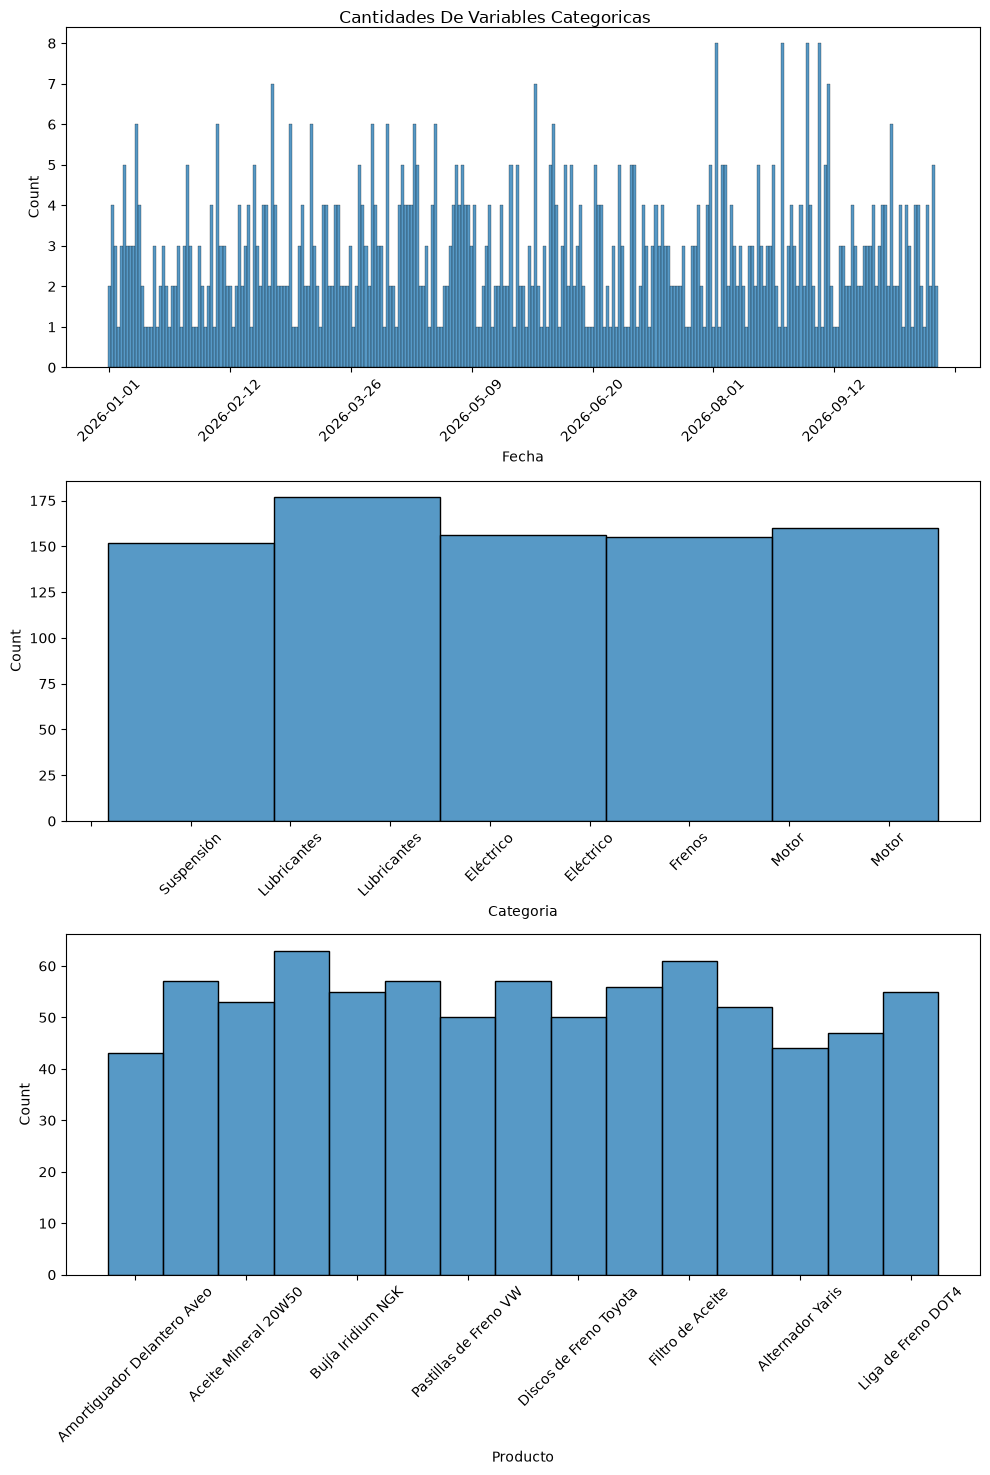

In [58]:
# Analisis Categorico


fig, ax = plt.subplots(3,1,figsize = (10,15))

sns.histplot(ax =ax[0], data= ds, x=a)
sns.histplot(ax =ax[1], data= ds, x=b)
sns.histplot(ax =ax[2], data= ds, x=c)

for axis in ax:
    # 1. Inclina el texto 45 o 90 grados para que no choquen a los lados
    axis.tick_params(axis='x', rotation=45) 
    
    # 2. Obliga al gráfico a mostrar solo un máximo de 10 fechas (salta las intermedias)
    axis.xaxis.set_major_locator(ticker.MaxNLocator(nbins=10))

plt.suptitle('Cantidades De Variables Categoricas')
plt.tight_layout()
plt.show()

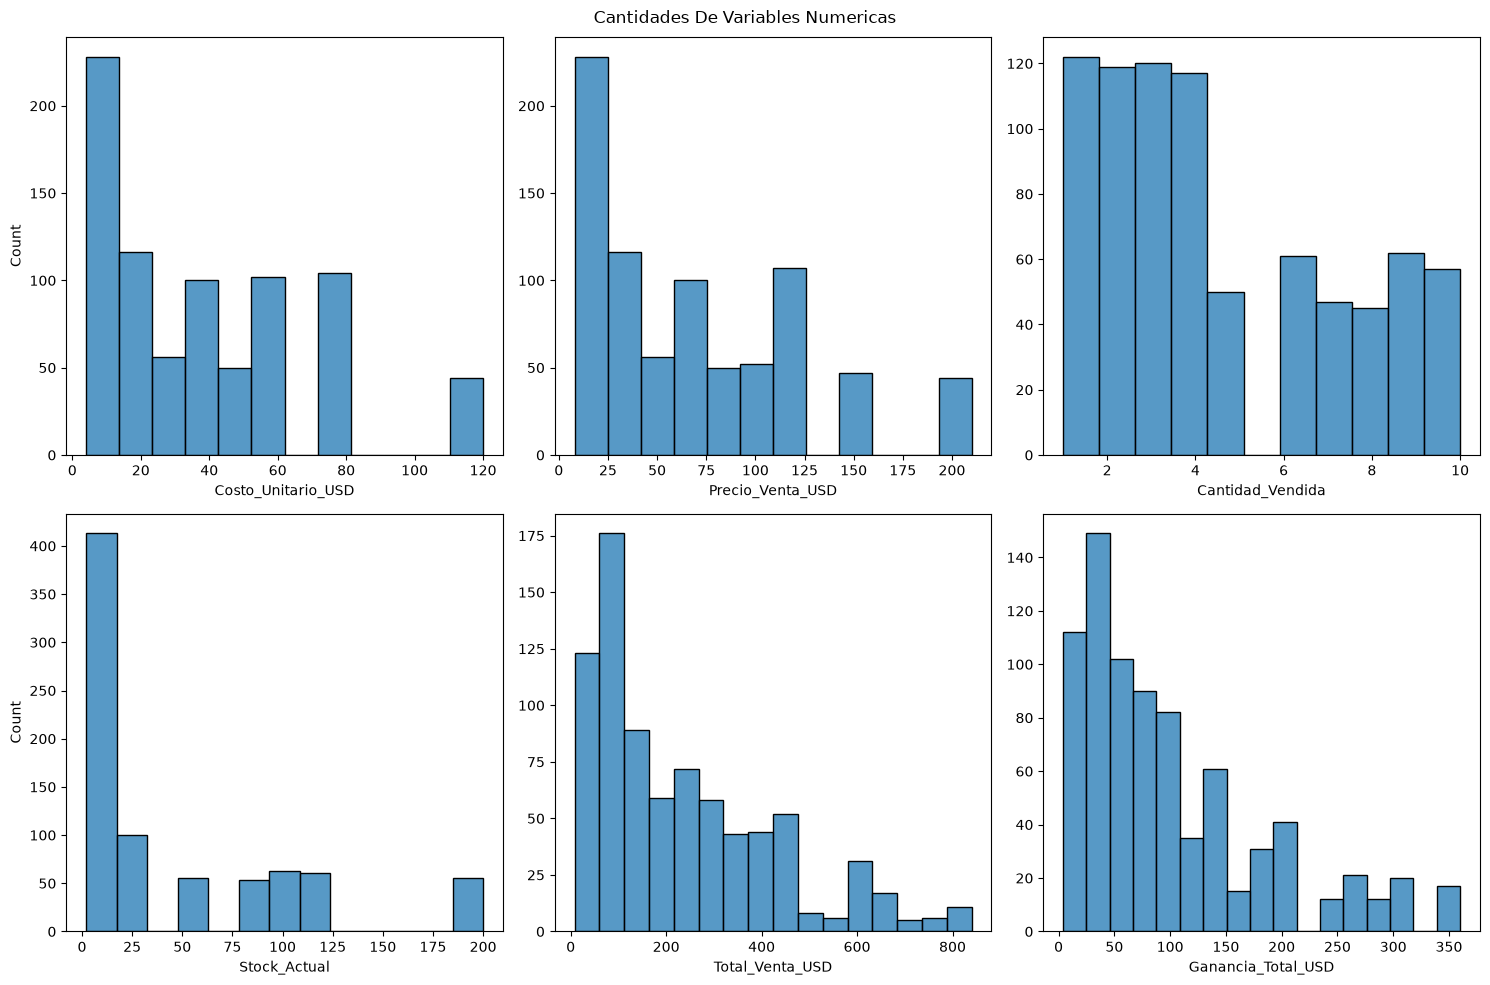

In [62]:
# Analisis Numerico


fig, ax = plt.subplots(2,3,figsize = (15,10))

sns.histplot(ax =ax[0,0], data= ds, x=uno)
sns.histplot(ax =ax[0,1], data= ds, x=dos).set(ylabel = None)
sns.histplot(ax =ax[0,2], data= ds, x=tres).set(ylabel = None)
sns.histplot(ax =ax[1,0], data= ds, x=cuatro)
sns.histplot(ax =ax[1,1], data= ds, x=cinco).set(ylabel = None)
sns.histplot(ax =ax[1,2], data= ds, x=seis).set(ylabel = None)



plt.suptitle('Cantidades De Variables Numericas')
plt.tight_layout()
plt.show()

# Analisis Multivariante

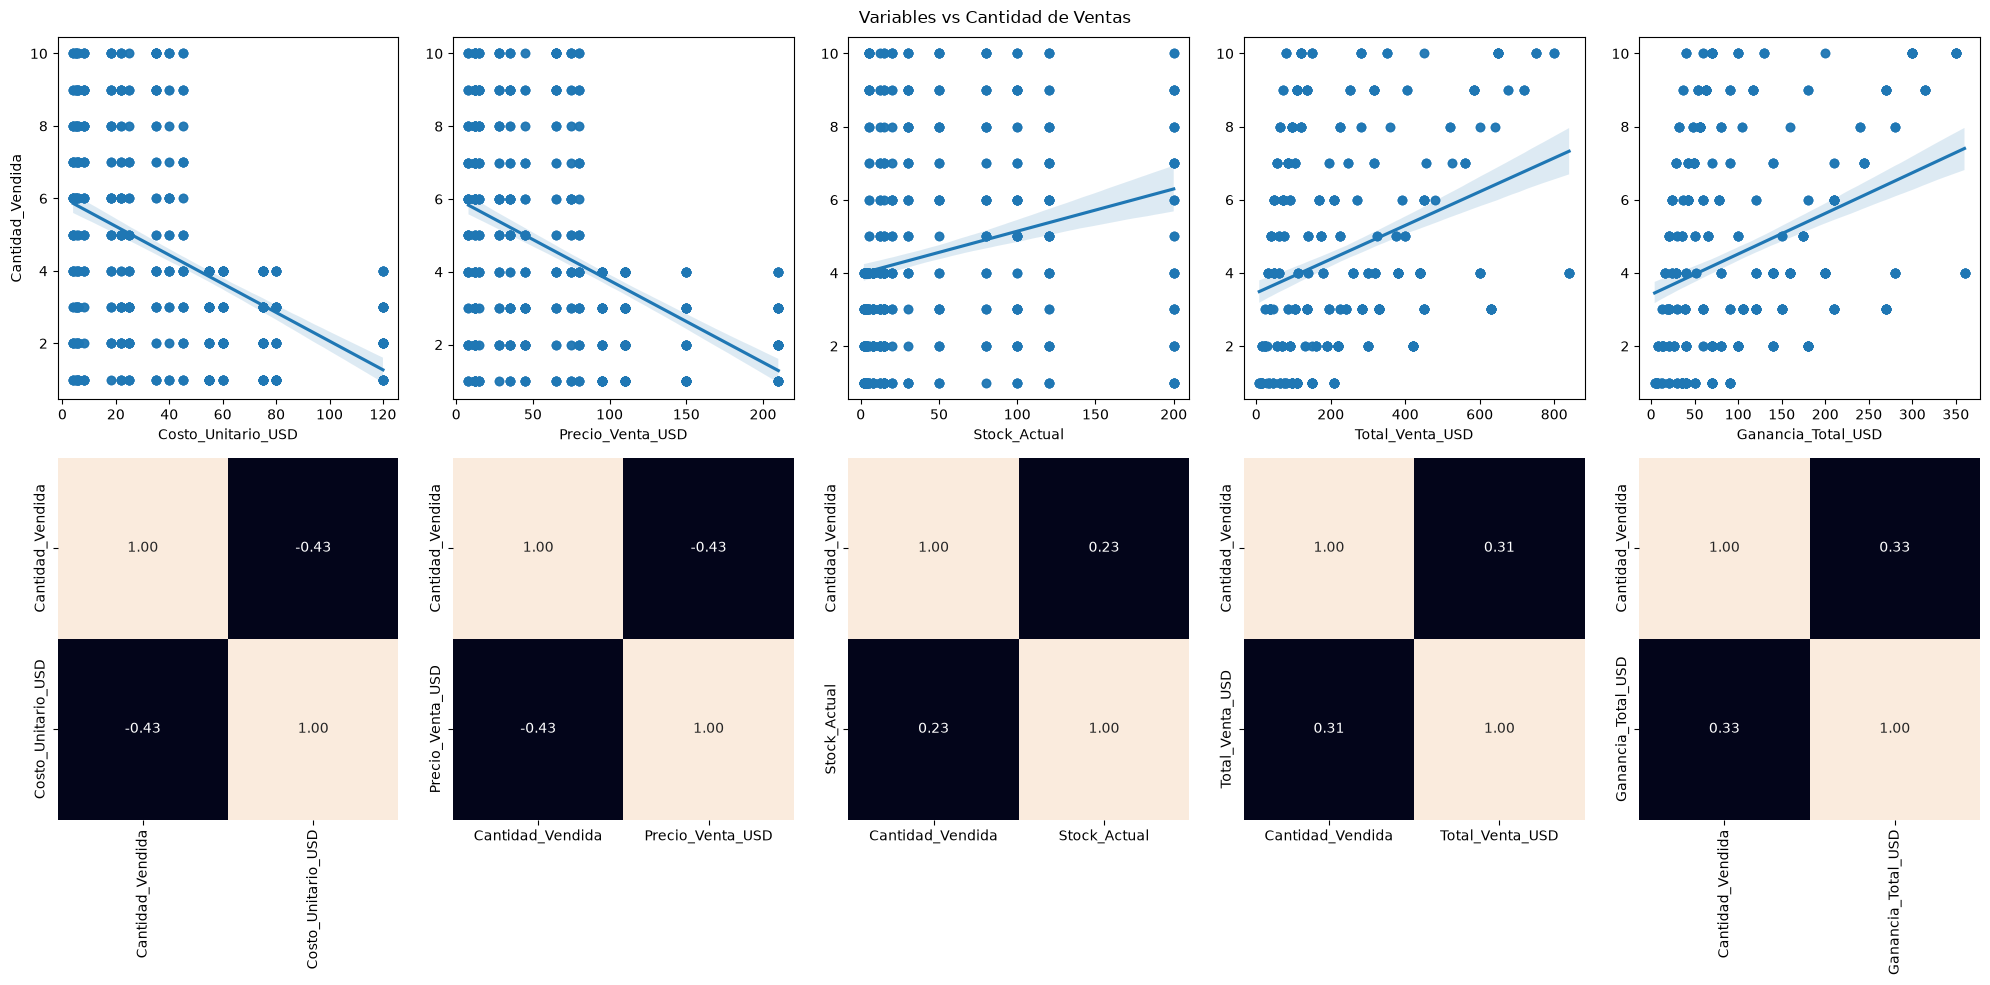

In [67]:
# Numerico - Numerico

fig, ax = plt.subplots(2,5,figsize=(20,10))

sns.regplot(ax =ax[0,0], data=  ds, x= uno, y=tres)
sns.heatmap(ds[[tres,uno]].corr(), annot= True, fmt= ".2f", ax=ax[1,0], cbar= False)
sns.regplot(ax =ax[0,1], data=  ds, x= dos, y=tres).set(ylabel = None)
sns.heatmap(ds[[tres,dos]].corr(), annot= True, fmt= ".2f", ax=ax[1,1], cbar= False)
sns.regplot(ax =ax[0,2], data=  ds, x= cuatro, y=tres).set(ylabel = None)
sns.heatmap(ds[[tres,cuatro]].corr(), annot= True, fmt= ".2f", ax=ax[1,2], cbar= False)
sns.regplot(ax =ax[0,3], data=  ds, x= cinco, y=tres).set(ylabel = None)
sns.heatmap(ds[[tres,cinco]].corr(), annot= True, fmt= ".2f", ax=ax[1,3], cbar= False)
sns.regplot(ax =ax[0,4], data=  ds, x= seis, y=tres).set(ylabel = None)
sns.heatmap(ds[[tres,seis]].corr(), annot= True, fmt= ".2f", ax=ax[1,4], cbar= False)

plt.suptitle('Variables vs Cantidad de Ventas')
plt.tight_layout()
plt.show()

### 📊 Resumen de Análisis Exploratorio (EDA): Variables vs. Volumen de Ventas

Tras evaluar las matrices de dispersión y los mapas de correlación de Pearson, se identificaron tres patrones clave en el comportamiento comercial del inventario:

**1. Efecto Precio-Demanda (Correlación de -0.43):**
*   **Hallazgo Técnico:** Existe una correlación negativa moderada entre el costo/precio unitario de un producto y la cantidad vendida.
*   **Interpretación de Negocio:** A medida que el precio del repuesto aumenta, el volumen de compra cae drásticamente. Los productos económicos (menores a $50) son el motor transaccional, con picos de hasta 10 unidades por factura. Las piezas que superan los $100 (ej. Alternadores) rara vez superan las 4 unidades por transacción. El flujo de caja diario depende de no tener quiebres de stock en mercancía barata de alta rotación (ej. bujías, ligas de freno).

**2. Rentabilidad impulsada por Volumen (Correlación de +0.33):**
*   **Hallazgo Técnico:** La cantidad vendida presenta una correlación positiva directa con la ganancia neta generada.
*   **Interpretación de Negocio:** La rentabilidad del local se sostiene fuertemente sobre el volumen de ventas y no solo sobre el margen unitario. Vender masivamente productos de menor costo compensa con creces el margen generado por piezas costosas esporádicas.

**3. Ineficiencia de Capital Estancado (Correlación de +0.23):**
*   **Hallazgo Técnico:** La relación entre el stock actual en almacén y el histórico de cantidad vendida es sumamente débil (+0.23).
*   **Interpretación de Negocio:** Las compras a proveedores no están optimizadas según la demanda real. El negocio acumula niveles de inventario similares para productos que rotan rápido y para productos que no se venden. Esto indica que hay capital inmovilizado en estantes, justificando la implementación inmediata de un modelo de series temporales para predecir compras futuras.

In [68]:
# Factorizo para analizar numerico categorico

ds[a] = pd.factorize(ds[a])[0]
ds[b] = pd.factorize(ds[b])[0]
ds[c] = pd.factorize(ds[c])[0]

ds.head()

,Fecha,Categoria,Producto,Costo_Unitario_USD,Precio_Venta_USD,Cantidad_Vendida,Stock_Actual,Total_Venta_USD,Ganancia_Total_USD
0,0,0,0,40,75,4,20,300,140
1,0,0,1,8,15,9,30,135,63
2,1,1,2,18,28,1,80,28,10
3,1,1,3,22,35,6,100,210,78
4,1,2,4,6,12,7,200,84,42


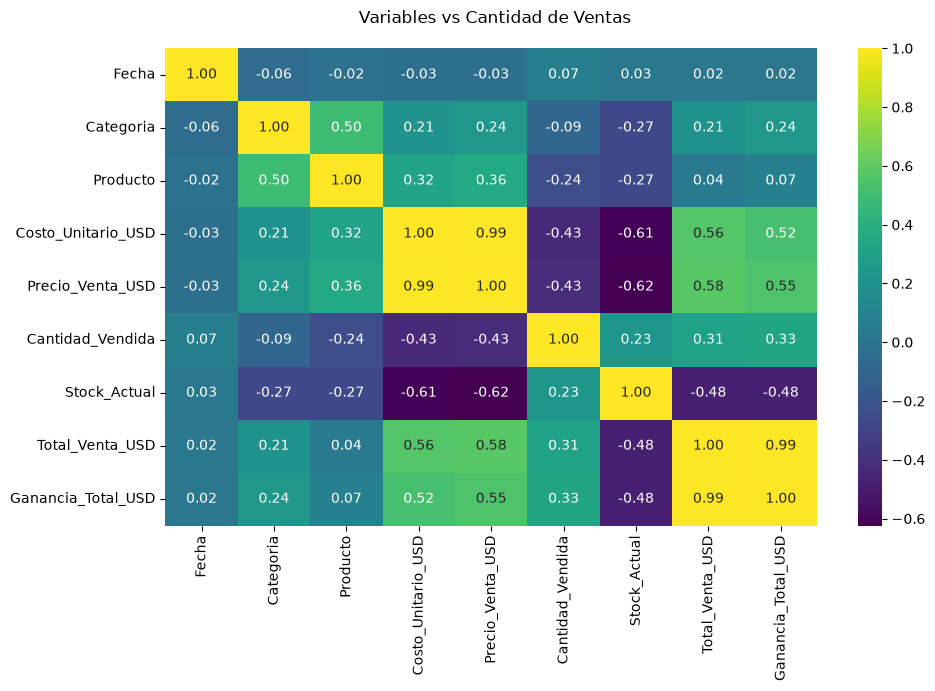

In [72]:
fig, ax =  plt.subplots(figsize = (10,7))

sns.heatmap(ds.corr(method="pearson"), annot= True, fmt= ".2f",cmap='viridis', ax =  ax)

plt.suptitle('Variables vs Cantidad de Ventas')
plt.tight_layout()
plt.show()


# Analisis de Outliers

In [73]:
ds.describe()

,Fecha,Categoria,Producto,Costo_Unitario_USD,Precio_Venta_USD,Cantidad_Vendida,Stock_Actual,Total_Venta_USD,Ganancia_Total_USD
count,800.00000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,139.57625,1.992500,6.938750,37.731250,66.002500,4.526250,46.970000,232.808750,100.837500
std,78.70338,1.406206,4.245884,31.323042,54.166017,2.854733,56.236085,190.985009,84.577022
min,0.00000,0.000000,0.000000,4.000000,8.000000,1.000000,2.000000,8.000000,4.000000
25%,73.00000,1.000000,3.000000,8.000000,15.000000,2.000000,7.250000,84.000000,39.000000
50%,139.50000,2.000000,7.000000,30.000000,55.000000,4.000000,15.000000,175.000000,70.000000
75%,209.00000,3.000000,10.000000,55.000000,95.000000,7.000000,80.000000,330.000000,140.000000
max,274.00000,4.000000,14.000000,120.000000,210.000000,10.000000,200.000000,840.000000,360.000000
